## Step 1: Import the required libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Load the dataset

In [2]:
# Load dataset
df = pd.read_excel("Raw Data Supermaket Sales.xlsx")

# Display first five rows
print(df.head())

# Dataset dimensions
print("\nDataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

    Invoice ID Branch       City Customer type  Gender  \
0  750-67-8428      A     Yangon        Member  Female   
1  226-31-3081      C  Naypyitaw        Normal  Female   
2  631-41-3108      A     Yangon        Normal    Male   
3  123-19-1176      A     Yangon        Member    Male   
4  373-73-7910      A     Yangon        Normal    Male   

             Product line  Unit price  Quantity   Tax 5%     Total  Month  \
0       Health and beauty       74.69         7  26.1415  548.9715      1   
1  Electronic accessories       15.28         5   3.8200   80.2200      3   
2      Home and lifestyle       46.33         7  16.2155  340.5255      3   
3       Health and beauty       58.22         8  23.2880  489.0480      1   
4       Sports and travel       86.31         7  30.2085  634.3785      2   

   Day  Year       Date      Time      Payment    cogs  \
0    5  2019 2019-01-05  13:08:00      Ewallet  522.83   
1    8  2019 2019-03-08  10:29:00         Cash   76.40   
2    3  2019 2

## Step 3: Prepare the dataset

In [3]:
# Convert relevant columns to numeric
numeric_columns = [
    "Unit price",
    "Quantity",
    "Rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Create a day-of-week feature
df["Day_of_Week"] = df["Date"].dt.dayofweek

# Select the columns needed for modelling
features = [
    "Branch",
    "Customer type",
    "Gender",
    "Unit price",
    "Quantity",
    "Payment",
    "Rating",
    "Day_of_Week"
]

target = "Product line"

# Keep only the selected columns
model_df = df[features + [target]].copy()

# Remove rows with missing values in required columns
model_df = model_df.dropna(subset=features + [target])

print("Prepared dataset shape:", model_df.shape)

print("\nMissing values after preparation:")
print(model_df.isnull().sum())

print("\nTarget distribution:")
print(model_df[target].value_counts())

Prepared dataset shape: (1000, 9)

Missing values after preparation:
Branch           0
Customer type    0
Gender           0
Unit price       0
Quantity         0
Payment          0
Rating           0
Day_of_Week      0
Product line     0
dtype: int64

Target distribution:
Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64


## Step 4: Separate features and target

In [4]:
# Input features
X = model_df[features]

# Target variable
y = model_df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget categories:")
print(y.unique())

Features shape: (1000, 8)
Target shape: (1000,)

Target categories:
['Health and beauty' 'Electronic accessories' 'Home and lifestyle'
 'Sports and travel' 'Food and beverages' 'Fashion accessories']


## Step 5: Split the dataset into training and testing sets

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (800, 8)
Testing features: (200, 8)

Training target distribution:
Product line
Fashion accessories       142
Food and beverages        139
Electronic accessories    136
Sports and travel         133
Home and lifestyle        128
Health and beauty         122
Name: count, dtype: int64

Testing target distribution:
Product line
Fashion accessories       36
Food and beverages        35
Electronic accessories    34
Sports and travel         33
Home and lifestyle        32
Health and beauty         30
Name: count, dtype: int64


## Step 6: Preprocess categorical and numerical features

In [6]:
# Categorical features
categorical_features = [
    "Branch",
    "Customer type",
    "Gender",
    "Payment"
]

# Numerical features
numerical_features = [
    "Unit price",
    "Quantity",
    "Rating",
    "Day_of_Week"
]

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Preprocessing for numerical features
numerical_transformer = StandardScaler()

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


## Step 7: Train Model 1 — Logistic Regression

In [7]:
# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [8]:
# Predict the product line
y_pred_lr = logistic_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10].tolist())

First 10 actual values:
['Sports and travel', 'Electronic accessories', 'Home and lifestyle', 'Electronic accessories', 'Sports and travel', 'Electronic accessories', 'Health and beauty', 'Health and beauty', 'Sports and travel', 'Fashion accessories']

First 10 predicted values:
['Food and beverages', 'Sports and travel', 'Fashion accessories', 'Electronic accessories', 'Sports and travel', 'Electronic accessories', 'Food and beverages', 'Fashion accessories', 'Home and lifestyle', 'Home and lifestyle']


In [9]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

recall_lr = recall_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

f1_lr = f1_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_lr, 4))
print("Weighted Precision:", round(precision_lr, 4))
print("Weighted Recall:", round(recall_lr, 4))
print("Weighted F1-score:", round(f1_lr, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.18
Weighted Precision: 0.1752
Weighted Recall: 0.18
Weighted F1-score: 0.1752

Classification Report:
                        precision    recall  f1-score   support

Electronic accessories       0.20      0.24      0.21        34
   Fashion accessories       0.18      0.25      0.21        36
    Food and beverages       0.17      0.17      0.17        35
     Health and beauty       0.05      0.03      0.04        30
    Home and lifestyle       0.19      0.16      0.17        32
     Sports and travel       0.26      0.21      0.23        33

              accuracy                           0.18       200
             macro avg       0.17      0.18      0.17       200
          weighted avg       0.18      0.18      0.18       200



## Step 8: Train Model 2 — Random Forest Classifier

In [10]:
# Create Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [11]:
# Predict product line
y_pred_rf = rf_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10].tolist())

First 10 actual values:
['Sports and travel', 'Electronic accessories', 'Home and lifestyle', 'Electronic accessories', 'Sports and travel', 'Electronic accessories', 'Health and beauty', 'Health and beauty', 'Sports and travel', 'Fashion accessories']

First 10 predicted values:
['Food and beverages', 'Sports and travel', 'Fashion accessories', 'Home and lifestyle', 'Sports and travel', 'Health and beauty', 'Sports and travel', 'Fashion accessories', 'Health and beauty', 'Food and beverages']


In [12]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", round(accuracy_rf, 4))
print("Weighted Precision:", round(precision_rf, 4))
print("Weighted Recall:", round(recall_rf, 4))
print("Weighted F1-score:", round(f1_rf, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.155
Weighted Precision: 0.153
Weighted Recall: 0.155
Weighted F1-score: 0.1534

Classification Report:
                        precision    recall  f1-score   support

Electronic accessories       0.12      0.12      0.12        34
   Fashion accessories       0.16      0.17      0.16        36
    Food and beverages       0.18      0.17      0.18        35
     Health and beauty       0.07      0.07      0.07        30
    Home and lifestyle       0.18      0.16      0.17        32
     Sports and travel       0.20      0.24      0.22        33

              accuracy                           0.15       200
             macro avg       0.15      0.15      0.15       200
          weighted avg       0.15      0.15      0.15       200



## Step 9: Compare both models

In [13]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_rf
    ],
    "Weighted Precision": [
        precision_lr,
        precision_rf
    ],
    "Weighted Recall": [
        recall_lr,
        recall_rf
    ],
    "Weighted F1-score": [
        f1_lr,
        f1_rf
    ]
})

print(model_comparison.round(4))

                 Model  Accuracy  Weighted Precision  Weighted Recall  \
0  Logistic Regression     0.180              0.1752            0.180   
1        Random Forest     0.155              0.1530            0.155   

   Weighted F1-score  
0             0.1752  
1             0.1534  


## Step 10: Perform cross-validation

In [14]:
# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression cross-validation
lr_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Random Forest cross-validation
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("LOGISTIC REGRESSION CROSS-VALIDATION")
print(lr_cv_scores)
print("Mean accuracy:", lr_cv_scores.mean())
print("Standard deviation:", lr_cv_scores.std())

print("\nRANDOM FOREST CROSS-VALIDATION")
print(rf_cv_scores)
print("Mean accuracy:", rf_cv_scores.mean())
print("Standard deviation:", rf_cv_scores.std())

LOGISTIC REGRESSION CROSS-VALIDATION
[0.20625 0.1625  0.16875 0.15    0.15   ]
Mean accuracy: 0.16750000000000004
Standard deviation: 0.020691181696558557

RANDOM FOREST CROSS-VALIDATION
[0.19375 0.2125  0.11875 0.14375 0.13125]
Mean accuracy: 0.15999999999999998
Standard deviation: 0.03657184709581949


## Step 11: Hyperparameter tuning using Grid Search

In [15]:
# Parameter combinations to test
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

# Grid Search with cross-validation
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# Fit Grid Search on training data
grid_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Best Cross-Validation Accuracy:
0.17375000000000002


## Step 12: Evaluate the tuned model

In [16]:
# Retrieve the best model
best_rf_model = grid_search.best_estimator_

# Predict the test set
y_pred_tuned = best_rf_model.predict(X_test)

# Calculate metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

tuned_precision = precision_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

print("TUNED RANDOM FOREST RESULTS")
print("---------------------------")

print("Accuracy:", round(tuned_accuracy, 4))
print("Weighted Precision:", round(tuned_precision, 4))
print("Weighted Recall:", round(tuned_recall, 4))
print("Weighted F1-score:", round(tuned_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    zero_division=0
))

TUNED RANDOM FOREST RESULTS
---------------------------
Accuracy: 0.15
Weighted Precision: 0.149
Weighted Recall: 0.15
Weighted F1-score: 0.1485

Classification Report:
                        precision    recall  f1-score   support

Electronic accessories       0.19      0.24      0.21        34
   Fashion accessories       0.11      0.08      0.10        36
    Food and beverages       0.11      0.11      0.11        35
     Health and beauty       0.09      0.10      0.10        30
    Home and lifestyle       0.16      0.16      0.16        32
     Sports and travel       0.23      0.21      0.22        33

              accuracy                           0.15       200
             macro avg       0.15      0.15      0.15       200
          weighted avg       0.15      0.15      0.15       200



## Step 13: Create a confusion matrix

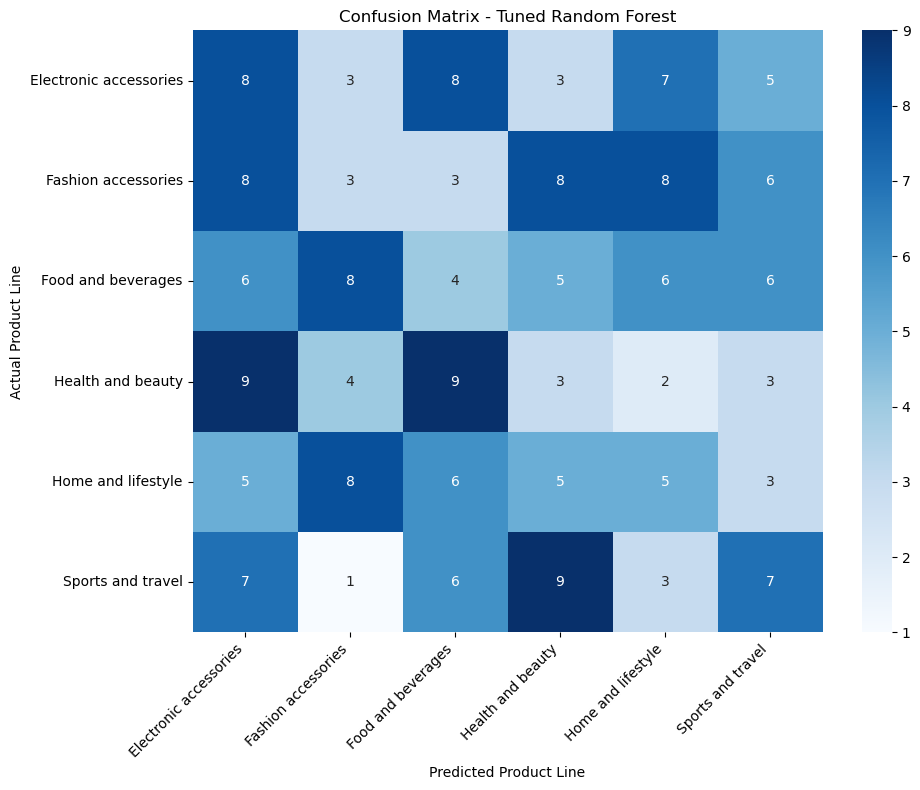

In [17]:
# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=best_rf_model.classes_
)

# Visualize the confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_rf_model.classes_,
    yticklabels=best_rf_model.classes_
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Product Line")
plt.ylabel("Actual Product Line")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 14: Analyze feature importance

In [18]:
# Retrieve the fitted preprocessing component
fitted_preprocessor = best_rf_model.named_steps["preprocessor"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importances = (
    best_rf_model.named_steps["classifier"].feature_importances_
)

# Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                              Feature  Importance
10              numerical__Unit price    0.218816
12                  numerical__Rating    0.198672
11                numerical__Quantity    0.150443
13             numerical__Day_of_Week    0.138658
4   categorical__Customer type_Normal    0.032446
7           categorical__Payment_Cash    0.031729
2               categorical__Branch_C    0.031126
5          categorical__Gender_Female    0.030545
9        categorical__Payment_Ewallet    0.028866
0               categorical__Branch_A    0.028761
3   categorical__Customer type_Member    0.028409
8    categorical__Payment_Credit card    0.028409
1               categorical__Branch_B    0.026958
6            categorical__Gender_Male    0.026163


## Step 15: Save the model evaluation results

In [19]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_rf,
        tuned_accuracy
    ],
    "Weighted Precision": [
        precision_lr,
        precision_rf,
        tuned_precision
    ],
    "Weighted Recall": [
        recall_lr,
        recall_rf,
        tuned_recall
    ],
    "Weighted F1-score": [
        f1_lr,
        f1_rf,
        tuned_f1
    ]
})

print(final_results.round(4))

final_results.to_csv(
    "Week5_Model_Evaluation_Results.csv",
    index=False
)

print("Model evaluation results saved successfully!")

                 Model  Accuracy  Weighted Precision  Weighted Recall  \
0  Logistic Regression     0.180              0.1752            0.180   
1        Random Forest     0.155              0.1530            0.155   
2  Tuned Random Forest     0.150              0.1490            0.150   

   Weighted F1-score  
0             0.1752  
1             0.1534  
2             0.1485  
Model evaluation results saved successfully!


In [ ]:
Step 16: Optional — Plot the ROC curve